# 01 - Exploring and Cleaning the NFIP Flood Claims Data

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

In this notebook we look at the data for the first time, find the problems in it and clean it.
At the end we save a clean file. The three research question notebooks (02, 03, 04) use that file.

**Our data:** FEMA OpenFEMA *NFIP Redacted Claims v3*. One row is one flood insurance claim.
We only use claims with a loss year from **2020 to 2025**.

**Our research questions**

| | Question | Type of problem |
|---|---|---|
| RQ1 | Can we predict the dollar amount paid on a building claim using flood-zone, construction, policy and geographic features? | Regression |
| RQ2 | Can we predict if a claim is high severity (top 20% of building damage)? | Classification |
| RQ3 | Do claims form groups with similar flood risk? | Clustering |

**Plan**
1. Load the data, what each column means, attribute types
2. Missing values (with a correlation matrix of the blanks)
3. Duplicates
4. Noise and outliers
5. Leakage: columns we cannot use
6. New features
7. A few charts to understand the data
8. Fill the missing values and save

## 1. Load the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)

RAW_FILE = '/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet'
full = pd.read_parquet(RAW_FILE)
print('Claims in the whole file:', f'{len(full):,}')

df = full[full['yearOfLoss'].between(2020, 2025)].reset_index(drop=True)
del full
print('Claims from 2020 to 2025:', f'{len(df):,}')
print('Columns:', df.shape[1])

Claims in the whole file: 2,725,989


Claims from 2020 to 2025: 277,033
Columns: 84


Some columns are stored in a special number format (Decimal) and the dates use a type that pandas does not treat as dates.
We change them to normal numbers and dates first, otherwise pandas cannot calculate with them.
A few dates are impossible (for example the year 1069), so we turn years before 1800 into missing.

In [2]:
from decimal import Decimal
DATE_COLS = ['dateOfLoss', 'originalConstructionDate', 'originalNBDate', 'openDate', 'mostRecentPaymentDate', 'mostRecentRecoveryDate']
for c in DATE_COLS:
    d = pd.to_datetime(df[c].astype(str), errors='coerce', format='%Y-%m-%d')
    df[c] = d.where(d.dt.year >= 1800)
for c in df.columns:
    first = df[c].dropna().head(1)
    if len(first) and isinstance(first.iloc[0], Decimal):     # money columns stored as Decimal
        df[c] = df[c].astype(float)
print(df.dtypes.value_counts())
df.head(3)

float64                41
object                 22
bool                   11
datetime64[ns]          6
int16                   2
datetime64[us, UTC]     1
int64                   1
Name: count, dtype: int64


,agricultureStructureIndicator,asOfDate,basementEnclosureCrawlspaceType,policyCount,crsClassCode,dateOfLoss,elevatedBuildingIndicator,elevationCertificateIndicator,elevationDifference,baseFloodElevation,ratedFloodZone,houseWorship,locationOfContents,lowestAdjacentGrade,lowestFloorElevation,numberOfFloorsInTheInsuredBuilding,nonProfitIndicator,obstructionType,occupancyType,originalConstructionDate,originalNBDate,amountPaidOnBuildingClaim,amountPaidOnContentsClaim,amountPaidOnIncreasedCostOfComplianceClaim,postFIRMConstructionIndicator,rateMethod,smallBusinessIndicatorBuilding,totalBuildingInsuranceCoverage,totalContentsInsuranceCoverage,yearOfLoss,primaryResidenceIndicator,buildingDamageAmount,buildingDeductibleCode,netBuildingPaymentAmount,buildingPropertyValue,causeOfDamage,condominiumCoverageTypeCode,contentsDamageAmount,contentsDeductibleCode,netContentsPaymentAmount,contentsPropertyValue,disasterAssistanceCoverageRequired,eventDesignationNumber,ficoNumber,floodCharacteristicsIndicator,floodWaterDuration,floodproofedIndicator,floodEvent,iccCoverage,netIccPaymentAmount,nfipRatedCommunityNumber,nfipCommunityNumberCurrent,nfipCommunityName,nonPaymentReasonContents,nonPaymentReasonBuilding,numberOfUnits,buildingReplacementCost,contentsReplacementCost,replacementCostBasis,stateOwnedIndicator,waterDepth,floodZoneCurrent,buildingDescriptionCode,rentalPropertyIndicator,state,reportedCity,reportedZipCode,countyCode,censusGeoid,latitude,longitude,foundationType,openDate,mostRecentRecoveryDate,exteriorWaterDepth,interiorWaterDepth,mostRecentPaymentDate,preFirmIndicator,totalSalvageRecovery,totalBldgClaimPmtRecovery,totalContentsClaimPmtRecovery,totalIccClaimPmtRecovery,totalSubrogationRecovery,id
0,False,2026-09-08 00:00:00+00:00,0.0,1,7.0,2024-09-26,False,None,NaN,NaN,AE,False,NaN,NaN,NaN,2.0,False,NaN,18.0,1960-01-01,2003-06-12,500000.00,0.0,0.0,False,RE,False,500000.0,0.0,2024,False,571913.0,E,500000.00,2265817.0,4,N,NaN,None,0.0,NaN,NaN,FL0124,NaN,NaN,NaN,False,Hurricane Helene,30000.0,0.0,125133,125133,"NORTH REDINGTON BEACH, TOWN OF",None,None,15.0,2578394.0,NaN,A,False,0.0,VE,1.0,False,FL,Currently Unavailable,33708,12103,121030277011,27.8,-82.8,1,2024-09-27,NaT,46.0,0.0,2025-01-19,False,NaN,NaN,NaN,NaN,NaN,5448679
1,False,2026-09-08 00:00:00+00:00,0.0,2,5.0,2022-09-28,True,3,0.0,10.0,AE,False,NaN,3.9,10.0,1.0,False,15.0,15.0,1996-02-26,2011-02-28,243827.07,0.0,0.0,True,RE,False,500000.0,0.0,2022,False,245077.0,F,243827.07,0.0,1,A,1.0,None,0.0,0.0,0.0,FL0222,NaN,NaN,NaN,False,Hurricane Ian,30000.0,0.0,125124,125124,LEE COUNTY*,None,None,2.0,0.0,0.0,A,False,3.0,AE,1.0,False,FL,Currently Unavailable,33908,12071,120710501061,26.5,-81.9,6,2022-10-01,NaT,65.0,3.0,2023-01-04,False,NaN,NaN,NaN,NaN,NaN,5448693
2,False,2026-09-08 00:00:00+00:00,NaN,1,NaN,2022-07-28,True,None,1.0,920.0,AE,False,NaN,921.4,924.7,5.0,False,50.0,14.0,2000-07-01,2006-07-24,13920.08,0.0,0.0,True,RE,False,129000.0,0.0,2022,False,12757.0,F,13920.08,94727.0,4,N,NaN,None,0.0,NaN,NaN,None,NaN,NaN,NaN,False,Late July Flooding,30000.0,0.0,210069,210069,FLOYD COUNTY *,None,None,1.0,142354.0,NaN,A,False,0.0,AE,1.0,False,KY,Currently Unavailable,41606,21071,210719205004,37.4,-82.7,6,2022-08-01,NaT,10.0,9.0,2022-08-14,False,NaN,NaN,NaN,NaN,NaN,5448700


### 1.1 What each column means, and its attribute type

The descriptions are short versions of FEMA's data dictionary. The attribute types are:
**nominal** (names or codes, no order), **binary** (two values), **ordinal** (codes with an order),
**interval** (numbers or dates without a true zero) and **ratio** (numbers with a true zero, like dollars).

In [3]:
COLUMNS = {
    'agricultureStructureIndicator': ('Building is an agricultural structure', 'binary'),
    'asOfDate': ('Date the record was last updated by FEMA', 'interval'),
    'basementEnclosureCrawlspaceType': ('Code for basement, enclosure or crawlspace type', 'nominal'),
    'policyCount': ('Number of insured units under the policy', 'ratio'),
    'crsClassCode': ('Community Rating System class (1 = best flood protection, 10 = none)', 'ordinal'),
    'dateOfLoss': ('Date the flood water first entered the building', 'interval'),
    'elevatedBuildingIndicator': ('Building is elevated (NFIP definition)', 'binary'),
    'elevationCertificateIndicator': ('Code for how the elevation certificate was used in rating', 'nominal'),
    'elevationDifference': ('Lowest floor minus base flood elevation, in feet', 'interval'),
    'baseFloodElevation': ('Height of the 1% annual chance flood, in feet', 'interval'),
    'ratedFloodZone': ('Flood zone used to rate the policy (A, AE, V, X, ...)', 'nominal'),
    'houseWorship': ('Building is a house of worship', 'binary'),
    'locationOfContents': ('Code for where the contents are in the building', 'nominal'),
    'lowestAdjacentGrade': ('Lowest ground level next to the building, in feet', 'interval'),
    'lowestFloorElevation': ('Height of the lowest floor, in feet', 'interval'),
    'numberOfFloorsInTheInsuredBuilding': ('Code for the number of floors (5 = mobile home)', 'nominal'),
    'nonProfitIndicator': ('Owner is a non-profit organisation', 'binary'),
    'obstructionType': ('Code for obstructions under an elevated building', 'nominal'),
    'occupancyType': ('Code for the use of the building (single family, condo, business, ...)', 'nominal'),
    'originalConstructionDate': ('Date the building was built', 'interval'),
    'originalNBDate': ('Date the flood policy was first written', 'interval'),
    'amountPaidOnBuildingClaim': ('Dollars paid on the building claim (RQ1 target)', 'ratio'),
    'amountPaidOnContentsClaim': ('Dollars paid on the contents claim', 'ratio'),
    'amountPaidOnIncreasedCostOfComplianceClaim': ('Dollars paid to bring the building up to code (ICC)', 'ratio'),
    'postFIRMConstructionIndicator': ('Building was built after the first flood map (FIRM)', 'binary'),
    'rateMethod': ('Code for the rating method (RE = Risk Rating 2.0)', 'nominal'),
    'smallBusinessIndicatorBuilding': ('Owner is a small business (under 100 employees)', 'binary'),
    'totalBuildingInsuranceCoverage': ('Building insurance bought, in dollars', 'ratio'),
    'totalContentsInsuranceCoverage': ('Contents insurance bought, in dollars', 'ratio'),
    'yearOfLoss': ('Year of the flood', 'interval'),
    'primaryResidenceIndicator': ('Building is the main home of the owner', 'binary'),
    'buildingDamageAmount': ('Building damage measured by the adjuster, in dollars (RQ2 target)', 'ratio'),
    'buildingDeductibleCode': ('Code for the building deductible amount', 'ordinal'),
    'netBuildingPaymentAmount': ('Net building payment to the insured, in dollars', 'ratio'),
    'buildingPropertyValue': ('Value of the building estimated by the adjuster', 'ratio'),
    'causeOfDamage': ('Code for how the property was damaged', 'nominal'),
    'condominiumCoverageTypeCode': ('Code for the type of condominium coverage', 'nominal'),
    'contentsDamageAmount': ('Contents damage measured by the adjuster, in dollars', 'ratio'),
    'contentsDeductibleCode': ('Code for the contents deductible amount', 'ordinal'),
    'netContentsPaymentAmount': ('Net contents payment to the insured, in dollars', 'ratio'),
    'contentsPropertyValue': ('Value of the contents estimated by the adjuster', 'ratio'),
    'disasterAssistanceCoverageRequired': ('Code for the agency that required the flood insurance', 'nominal'),
    'eventDesignationNumber': ('ID of the catastrophe flood event', 'nominal'),
    'ficoNumber': ('Old number for a big flood event in a state (before June 2020)', 'nominal'),
    'floodCharacteristicsIndicator': ('Code for the type of flood water', 'nominal'),
    'floodWaterDuration': ('Hours the flood water stayed in the building', 'ratio'),
    'floodproofedIndicator': ('Building is floodproofed', 'binary'),
    'floodEvent': ('Name of the flood event (for example Hurricane Ian)', 'nominal'),
    'iccCoverage': ('Increased Cost of Compliance coverage, in dollars', 'ratio'),
    'netIccPaymentAmount': ('Net ICC payment, in dollars', 'ratio'),
    'nfipRatedCommunityNumber': ('ID of the NFIP community used for rating', 'nominal'),
    'nfipCommunityNumberCurrent': ('ID of the current NFIP community', 'nominal'),
    'nfipCommunityName': ('Name of the NFIP community', 'nominal'),
    'nonPaymentReasonContents': ('Reason the contents claim was closed without payment', 'nominal'),
    'nonPaymentReasonBuilding': ('Reason the building claim was closed without payment', 'nominal'),
    'numberOfUnits': ('Number of units in a condominium building', 'ratio'),
    'buildingReplacementCost': ('Cost to rebuild the building, in dollars', 'ratio'),
    'contentsReplacementCost': ('Cost to replace the contents, in dollars', 'ratio'),
    'replacementCostBasis': ('Claim settled on replacement cost (R) or actual cash value (A)', 'binary'),
    'stateOwnedIndicator': ('Property is owned by a state', 'binary'),
    'waterDepth': ('Depth of flood water in the building, in inches (sometimes feet)', 'ratio'),
    'floodZoneCurrent': ('Flood zone on the current flood map', 'nominal'),
    'buildingDescriptionCode': ('Code for the use of the building', 'nominal'),
    'rentalPropertyIndicator': ('Building is rented out', 'binary'),
    'state': ('State abbreviation', 'nominal'),
    'reportedCity': ('City (not available in this file)', 'nominal'),
    'reportedZipCode': ('ZIP code of the property', 'nominal'),
    'countyCode': ('County FIPS code', 'nominal'),
    'censusGeoid': ('Census block group code of the property', 'nominal'),
    'latitude': ('Latitude, rounded to 0.1 degree for privacy', 'interval'),
    'longitude': ('Longitude, rounded to 0.1 degree for privacy', 'interval'),
    'foundationType': ('Code for the foundation (1 slab, 2 basement, 3 crawlspace, 4-6 elevated, 0 not recorded)', 'nominal'),
    'openDate': ('Date the claim was opened (reported)', 'interval'),
    'mostRecentRecoveryDate': ('Date of the latest money recovered', 'interval'),
    'exteriorWaterDepth': ('Depth of flood water outside the building, in inches', 'interval'),
    'interiorWaterDepth': ('Depth of flood water inside the building, in inches', 'interval'),
    'mostRecentPaymentDate': ('Date of the latest payment on the claim', 'interval'),
    'preFirmIndicator': ('Building was built before the first flood map', 'binary'),
    'totalSalvageRecovery': ('Money recovered from salvage', 'ratio'),
    'totalBldgClaimPmtRecovery': ('Building payment that was paid back', 'ratio'),
    'totalContentsClaimPmtRecovery': ('Contents payment that was paid back', 'ratio'),
    'totalIccClaimPmtRecovery': ('ICC payment that was paid back', 'ratio'),
    'totalSubrogationRecovery': ('Money recovered from another party', 'ratio'),
    'id': ('Unique ID of the claim', 'nominal'),
}
columns_table = pd.DataFrame([(c, *COLUMNS.get(c, ('?', '?'))) for c in df.columns],
                             columns=['column', 'description', 'attribute type']).set_index('column')
print('Columns without a description:', [c for c in df.columns if c not in COLUMNS])
print(columns_table['attribute type'].value_counts())
pd.set_option('display.max_rows', 100); pd.set_option('display.max_colwidth', 100)
columns_table

Columns without a description: []
attribute type
nominal     29
ratio       24
interval    16
binary      12
ordinal      3
Name: count, dtype: int64


,description,attribute type
column,,
agricultureStructureIndicator,Building is an agricultural structure,binary
asOfDate,Date the record was last updated by FEMA,interval
basementEnclosureCrawlspaceType,"Code for basement, enclosure or crawlspace type",nominal
policyCount,Number of insured units under the policy,ratio
crsClassCode,"Community Rating System class (1 = best flood protection, 10 = none)",ordinal
dateOfLoss,Date the flood water first entered the building,interval
elevatedBuildingIndicator,Building is elevated (NFIP definition),binary
elevationCertificateIndicator,Code for how the elevation certificate was used in rating,nominal
elevationDifference,"Lowest floor minus base flood elevation, in feet",interval


Claims per loss year:
yearOfLoss
2020     33185
2021     46699
2022     60262
2023     21690
2024    102054
2025     13143
Name: count, dtype: int64


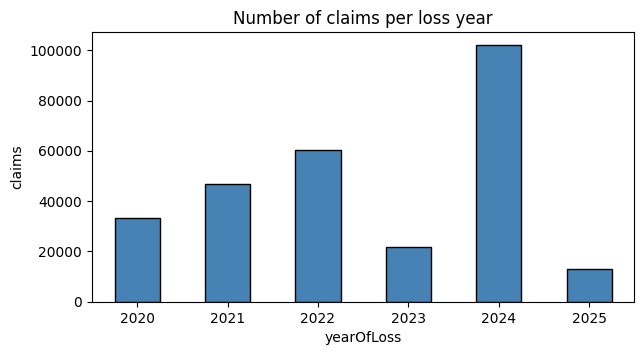

In [4]:
print('Claims per loss year:')
print(df['yearOfLoss'].value_counts().sort_index())
df['yearOfLoss'].value_counts().sort_index().plot.bar(color='steelblue', edgecolor='black', figsize=(7, 3.5))
plt.title('Number of claims per loss year'); plt.ylabel('claims'); plt.xticks(rotation=0); plt.show()

**What we see.** 2024 has by far the most claims (102,054). This is the year of Hurricanes Helene and Milton. 2022 is second (60,262, Hurricane Ian).
So a few big storms make most of our data. We have to remember this later: a model can learn "the storm" and not the building.
2025 has fewer claims; it had fewer big storms, and some 2025 claims may not be in the file yet.

## 2. Missing values

First we count the blanks in every column.

Columns with no missing values: 27 of 84


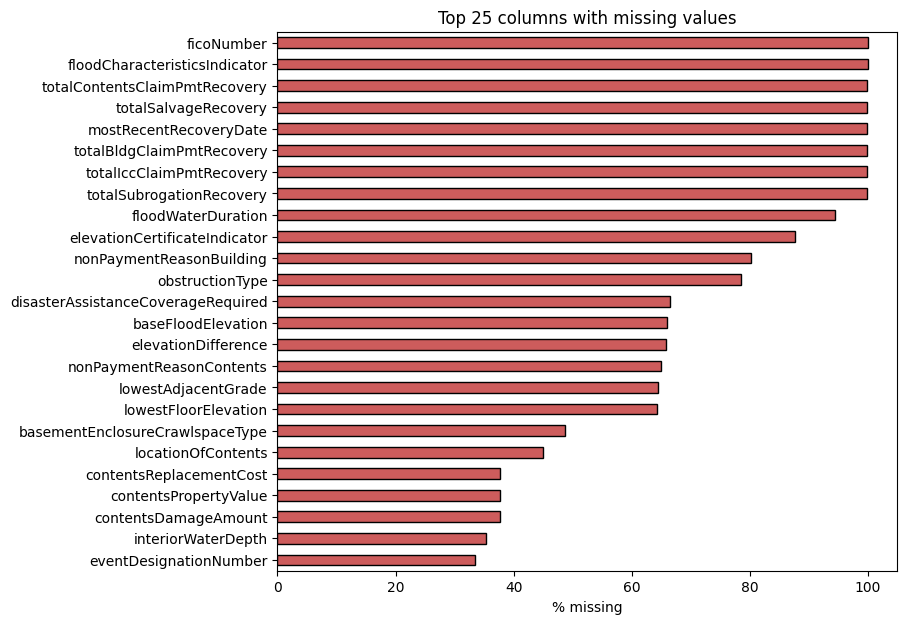

ficoNumber                            100.0
floodCharacteristicsIndicator         100.0
totalContentsClaimPmtRecovery          99.9
totalSalvageRecovery                   99.9
mostRecentRecoveryDate                 99.9
totalBldgClaimPmtRecovery              99.9
totalIccClaimPmtRecovery               99.9
totalSubrogationRecovery               99.9
floodWaterDuration                     94.4
elevationCertificateIndicator          87.7
nonPaymentReasonBuilding               80.2
obstructionType                        78.4
disasterAssistanceCoverageRequired     66.5
baseFloodElevation                     66.0
elevationDifference                    65.8
nonPaymentReasonContents               64.9
lowestAdjacentGrade                    64.5
lowestFloorElevation                   64.2
basementEnclosureCrawlspaceType        48.7
locationOfContents                     45.0
contentsReplacementCost                37.8
contentsPropertyValue                  37.8
contentsDamageAmount            

In [5]:
missing = df.isna().mean().sort_values(ascending=False) * 100
print('Columns with no missing values:', (missing == 0).sum(), 'of', len(missing))
missing[missing > 0].head(25).plot.barh(figsize=(8, 7), color='indianred', edgecolor='black')
plt.gca().invert_yaxis(); plt.xlabel('% missing'); plt.title('Top 25 columns with missing values'); plt.show()
missing[missing > 0].round(1).head(25)

### 2.1 Which columns are missing together?

We make a 0/1 table (1 = blank) and compute the **correlation matrix of the blanks**. A value near **1** means two columns are
blank in the same rows; near **0** means their blanks have nothing to do with each other. We only use columns that are
between 1% and 99% blank (a column that is always or never blank has no pattern to show).

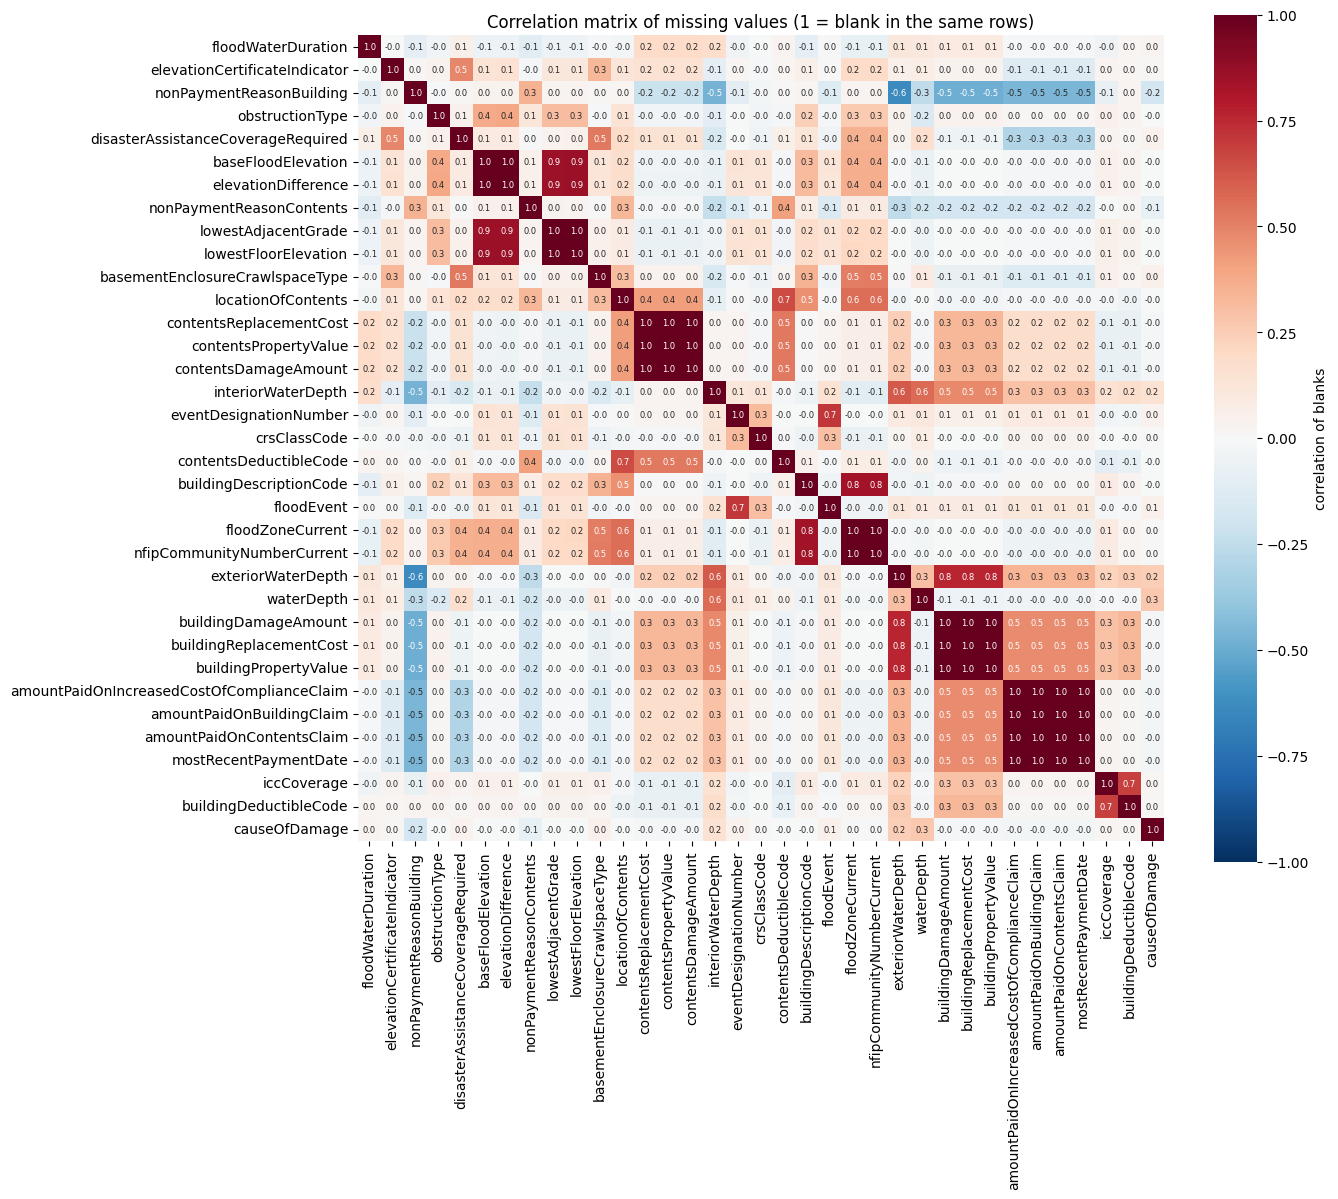

Pairs of columns that are blank together (correlation > 0.8):
amountPaidOnContentsClaim                   mostRecentPaymentDate         1.00
buildingDamageAmount                        buildingPropertyValue         1.00
amountPaidOnBuildingClaim                   mostRecentPaymentDate         1.00
                                            amountPaidOnContentsClaim     1.00
amountPaidOnIncreasedCostOfComplianceClaim  mostRecentPaymentDate         1.00
                                            amountPaidOnContentsClaim     1.00
contentsPropertyValue                       contentsDamageAmount          1.00
amountPaidOnIncreasedCostOfComplianceClaim  amountPaidOnBuildingClaim     1.00
buildingReplacementCost                     buildingPropertyValue         1.00
buildingDamageAmount                        buildingReplacementCost       1.00
contentsReplacementCost                     contentsPropertyValue         1.00
                                            contentsDamageAmount     

In [6]:
some_missing = missing[(missing > 1) & (missing < 99)].index
blank = df[some_missing].isna().astype(int)
blank_corr = blank.corr()
plt.figure(figsize=(13, 11))
sns.heatmap(blank_corr, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 6}, square=True,
            cbar_kws={'label': 'correlation of blanks'})
plt.title('Correlation matrix of missing values (1 = blank in the same rows)'); plt.show()

pairs = blank_corr.where(np.triu(np.ones(blank_corr.shape, dtype=bool), k=1)).stack()
print('Pairs of columns that are blank together (correlation > 0.8):')
print(pairs[pairs > 0.8].sort_values(ascending=False).round(2).to_string())

**What the matrix shows.** Several blocks of columns are always blank together:
- **Payment block:** the three payment columns and `mostRecentPaymentDate` (correlation 1.00). If a claim has no payment record, all of them are empty.
- **Inspection block:** `buildingDamageAmount`, `buildingPropertyValue` and `buildingReplacementCost` (1.00). These are filled in by
  the adjuster, so when there was no inspection, all three are missing. The same is true for the three contents columns.
- **Elevation block:** `baseFloodElevation`, `elevationDifference`, `lowestFloorElevation` and `lowestAdjacentGrade` (0.86 to 1.00).
  They all come from the elevation certificate, so a building without a certificate has none of them.
- **Current map block:** `floodZoneCurrent` and `nfipCommunityNumberCurrent` (1.00).

Columns in the same block are missing for the **same reason**, so in the next step we only have to find the reason once for each block.

### 2.2 Hidden missing values

Some columns have no blank, but use a special number that means "unknown". We found these by looking at the most common values:

In [7]:
print('waterDepth = 99            :', (df['waterDepth'] == 99).sum())
print('waterDepth >= 999          :', (df['waterDepth'] >= 999).sum())
print('baseFloodElevation >= 9000 :', (df['baseFloodElevation'].abs() >= 9000).sum())
print('elevationDifference >= 500 :', (df['elevationDifference'].abs() >= 500).sum())

df.loc[df['waterDepth'] >= 99, 'waterDepth'] = np.nan
df.loc[df['baseFloodElevation'].abs() >= 9000, 'baseFloodElevation'] = np.nan
df.loc[df['elevationDifference'].abs() >= 500, 'elevationDifference'] = np.nan
print('These placeholder values are now NaN.')

waterDepth = 99            : 12509
waterDepth >= 999          : 0
baseFloodElevation >= 9000 : 968
elevationDifference >= 500 : 13
These placeholder values are now NaN.


### 2.3 Which kind of missing is it?

A value can be missing for different reasons, and each reason needs a different fix:

| Kind | Meaning | Fix |
|---|---|---|
| **not applicable** | the value does not exist (no recovery → no recovery date) | leave it, a new category, or 0 |
| **missing with no pattern** | the blanks are random | fill with median / mode |
| **missing for a visible reason** | the blanks depend on another column we can see | fill inside groups, or add a "was missing" flag |
| **missing for a hidden reason** | the blanks depend on something we cannot see | be careful, add a flag |

**How we found the combinations to check.**
1. The matrix in 2.1 showed us which columns are blank **together** (for example all elevation columns). Columns that are blank
   together usually have the same reason, so we can check one of them for the whole block.
2. To find a **visible reason**, we need another column that "explains" the blanks. We thought about how the data is made and
   picked four columns that we can see for every claim:
   - **rating system** (legacy or Risk Rating 2.0): the two systems ask for different information;
   - **paid or not paid**: when nothing is paid, the adjuster may not measure everything;
   - **loss year** (2020-2021 or 2022-2025): FEMA added fields over time;
   - **Florida or not**: Florida has most claims and different storms.
3. For every column that is 1-99% blank, we compute the blank rate **inside each group** and the biggest gap between two groups.
   - gap of **10 points or more** → the blanks depend on that column → **visible reason**. For columns with very few blanks we also
     count a gap of 5 points or more if it is at least twice the blank rate (for example 6% in one group and 0% in the other);
   - very few blanks (under 1%) and small gaps → **no pattern**;
   - the value cannot exist for that claim (for example a recovery date when there was no recovery) → **not applicable**.
   A **hidden reason** cannot be proved from the data, because the reason is the missing value itself; we can only suspect it.

In [8]:
df['rating_system'] = np.where(df['rateMethod'] == 'RE', 'Risk Rating 2.0', 'legacy')
GROUPS = {'rating system': df['rating_system'],
          'paid or not': np.where(df['amountPaidOnBuildingClaim'].fillna(0) > 0, 'paid', 'not paid'),
          'loss year': np.where(df['yearOfLoss'] <= 2021, '2020-21', '2022-25'),
          'Florida or not': np.where(df['state'] == 'FL', 'FL', 'other')}
rows = []
for col in missing[(missing > 0) & (missing < 99)].index:
    row = {'column': col, '% missing': missing[col]}
    gaps = {}
    for gname, g in GROUPS.items():
        rate = df[col].isna().groupby(g).mean() * 100
        row[gname] = ' / '.join(f'{k} {v:.0f}%' for k, v in rate.items())
        gaps[gname] = rate.max() - rate.min()
    row['biggest gap (points)'] = max(gaps.values())
    row['gap from'] = max(gaps, key=gaps.get)
    rows.append(row)
why = pd.DataFrame(rows).set_index('column').round(1)
why

,% missing,rating system,paid or not,loss year,Florida or not,biggest gap (points),gap from
column,,,,,,,
floodWaterDuration,94.4,Risk Rating 2.0 94% / legacy 97%,not paid 97% / paid 94%,2020-21 100% / 2022-25 92%,FL 94% / other 95%,7.5,loss year
elevationCertificateIndicator,87.7,Risk Rating 2.0 88% / legacy 84%,not paid 87% / paid 88%,2020-21 85% / 2022-25 89%,FL 88% / other 87%,4.5,rating system
nonPaymentReasonBuilding,80.2,Risk Rating 2.0 81% / legacy 74%,not paid 15% / paid 100%,2020-21 76% / 2022-25 82%,FL 83% / other 77%,84.4,paid or not
obstructionType,78.4,Risk Rating 2.0 79% / legacy 73%,not paid 80% / paid 78%,2020-21 70% / 2022-25 82%,FL 83% / other 73%,12.1,loss year
disasterAssistanceCoverageRequired,66.5,Risk Rating 2.0 69% / legacy 49%,not paid 64% / paid 67%,2020-21 58% / 2022-25 70%,FL 68% / other 64%,19.8,rating system
baseFloodElevation,66.0,Risk Rating 2.0 66% / legacy 72%,not paid 64% / paid 67%,2020-21 64% / 2022-25 67%,FL 61% / other 73%,11.2,Florida or not
elevationDifference,65.8,Risk Rating 2.0 65% / legacy 71%,not paid 63% / paid 67%,2020-21 63% / 2022-25 67%,FL 61% / other 72%,11.1,Florida or not
nonPaymentReasonContents,64.9,Risk Rating 2.0 66% / legacy 56%,not paid 39% / paid 73%,2020-21 55% / 2022-25 69%,FL 71% / other 57%,33.5,paid or not
lowestAdjacentGrade,64.5,Risk Rating 2.0 64% / legacy 72%,not paid 63% / paid 65%,2020-21 65% / 2022-25 64%,FL 58% / other 72%,14.4,Florida or not


**Columns the rule cannot decide.** For a few columns the four groups do not show a clear gap. We checked them one by one:

In [9]:
print('floodWaterDuration - blank rate by loss year:')
print((df['floodWaterDuration'].isna().groupby(df['yearOfLoss']).mean() * 100).round(1).to_string())
print()
no_contents = df['totalContentsInsuranceCoverage'].fillna(0) == 0
print('contentsDeductibleCode - blank rate when there is no contents coverage:', f"{df.loc[no_contents, 'contentsDeductibleCode'].isna().mean():.1%}",
      '| when there is contents coverage:', f"{df.loc[~no_contents, 'contentsDeductibleCode'].isna().mean():.1%}")
print('elevationCertificateIndicator - blank rate by rating system:',
      (df['elevationCertificateIndicator'].isna().groupby(df['rating_system']).mean() * 100).round(1).to_dict())
print('causeOfDamage - % blank:', round(df['causeOfDamage'].isna().mean() * 100, 1))

floodWaterDuration - blank rate by loss year:
yearOfLoss
2020    99.9
2021    99.6
2022    98.0
2023    94.2
2024    91.0
2025    71.8

contentsDeductibleCode - blank rate when there is no contents coverage: 97.3% | when there is contents coverage: 0.0%
elevationCertificateIndicator - blank rate by rating system: {'Risk Rating 2.0': 88.1, 'legacy': 83.7}
causeOfDamage - % blank: 1.3


In [10]:
NOT_APPLICABLE = ['nonPaymentReasonBuilding', 'nonPaymentReasonContents', 'mostRecentPaymentDate', 'floodEvent',
                  'eventDesignationNumber', 'obstructionType', 'basementEnclosureCrawlspaceType', 'contentsDamageAmount',
                  'contentsPropertyValue', 'contentsReplacementCost', 'disasterAssistanceCoverageRequired', 'contentsDeductibleCode']
BY_HAND = {'floodWaterDuration': 'visible reason (loss year: a new field)',
           'elevationCertificateIndicator': 'not applicable (no elevation certificate)',
           'causeOfDamage': 'no pattern'}
def kind(row):
    if row.name in BY_HAND: return BY_HAND[row.name]
    if row.name in NOT_APPLICABLE: return 'not applicable'
    gap = row['biggest gap (points)']
    if gap >= 10 or (gap >= 5 and gap >= 2 * row['% missing']):
        return 'visible reason (' + row['gap from'] + ')'
    return 'no pattern'
why['kind of missing'] = why.apply(kind, axis=1)
print(why['kind of missing'].str.split(' \(').str[0].value_counts().to_string())
why[['% missing', 'biggest gap (points)', 'gap from', 'kind of missing']].sort_values('% missing', ascending=False)

kind of missing
visible reason    26
not applicable    13
no pattern        10


,% missing,biggest gap (points),gap from,kind of missing
column,,,,
floodWaterDuration,94.4,7.5,loss year,visible reason (loss year: a new field)
elevationCertificateIndicator,87.7,4.5,rating system,not applicable (no elevation certificate)
nonPaymentReasonBuilding,80.2,84.4,paid or not,not applicable
obstructionType,78.4,12.1,loss year,not applicable
disasterAssistanceCoverageRequired,66.5,19.8,rating system,not applicable
baseFloodElevation,66.0,11.2,Florida or not,visible reason (Florida or not)
elevationDifference,65.8,11.1,Florida or not,visible reason (Florida or not)
nonPaymentReasonContents,64.9,33.5,paid or not,not applicable
lowestAdjacentGrade,64.5,14.4,Florida or not,visible reason (Florida or not)


**What we found** (49 columns have some blanks)

| Kind of missing | Columns | Examples (blank rate inside the groups) |
|---|---|---|
| **visible reason** | 26 | `buildingDamageAmount`: 46.2% blank when nothing was paid, 0.5% when paid. `interiorWaterDepth`: 80% vs 22% (not paid / paid). `crsClassCode`: 8.5% blank in Florida, 55.9% elsewhere. `latitude`: 6.4% for legacy policies, 0.0% for Risk Rating 2.0. `floodZoneCurrent`: 0.1% in 2020-21, 28.3% in 2022-25. `floodWaterDuration`: 99.9% blank in 2020 and 71.8% in 2025, so FEMA started to fill it only recently |
| **not applicable** | 13 | `nonPaymentReasonBuilding` (no reason when the claim was paid), the contents columns (no contents insurance), `contentsDeductibleCode` (97.3% blank without contents coverage, 0.0% with it), `floodEvent` (no named storm) |
| **no pattern** | 10 | `countyCode`, `ratedFloodZone`, `numberOfFloorsInTheInsuredBuilding`: under 1% blank and no gap between groups |
| **hidden reason** | - | we cannot prove it from the data. We suspect it for damage on unpaid claims: small damage below the deductible may simply not be written down, so the blank depends on the (small) damage itself |

**What this means for the cleaning**
- **No pattern** columns are safe to fill with the median or mode.
- For **visible reason** columns, filling with one median for everybody is not ideal, because the blanks are not random.
  For example, CRS class is mostly blank **outside** Florida, so the Florida median would be used for other states. We still fill it
  with the median in section 8, but we know this is a weakness.
- `buildingDamageAmount` builds our RQ2 target, so we never fill it; claims without damage are left out of RQ2.

In section 2.2 we also found **hidden** missing values: numbers that mean "unknown".

## 3. Duplicates

Every row has its own `id`, so we compare **all columns except `id`**. Two rows that are the same in every other column are the same claim entered twice.

In [11]:
cols_no_id = [c for c in df.columns if c != 'id']
n_dup = df.duplicated(subset=cols_no_id).sum()
print('Duplicate rows (all columns except id):', n_dup)
df = df.drop_duplicates(subset=cols_no_id).reset_index(drop=True)
print('Rows after removing duplicates:', f'{len(df):,}')

Duplicate rows (all columns except id): 463


Rows after removing duplicates: 276,570


## 4. Noise and outliers

- **Noise** is a wrong value (a typo or an impossible value). We find it with a **rule**, not with a chart.
- **Outlier** is a real value that is far from the others. We keep it.

**How we look for noise.** We wrote down things that cannot happen in real life and counted the rows that break them:
1. a payment cannot be negative;
2. a building cannot be built after the flood that damaged it;
3. a claim cannot be opened before the flood happened;
4. a policy should not start after the flood (a claim needs a policy that was already active).

In [12]:
age_days = (df['dateOfLoss'] - df['originalConstructionDate']).dt.days
print('Rule 1 - negative building payment      :', (df['amountPaidOnBuildingClaim'] < 0).sum())
print('Rule 2 - building built AFTER the flood :', (age_days < 0).sum())
print('Rule 3 - claim opened BEFORE the flood  :', ((df['openDate'] - df['dateOfLoss']).dt.days < 0).sum())
print('Rule 4 - policy started AFTER the flood :', (df['originalNBDate'] > df['dateOfLoss']).sum())

df['amountPaidOnBuildingClaim'] = df['amountPaidOnBuildingClaim'].clip(lower=0)
df.loc[age_days < 0, 'originalConstructionDate'] = pd.NaT
df.loc[df['originalNBDate'] > df['dateOfLoss'], 'originalNBDate'] = pd.NaT
print('Fixed: negative payments -> 0, impossible dates -> missing.')

Rule 1 - negative building payment      : 35
Rule 2 - building built AFTER the flood : 90
Rule 3 - claim opened BEFORE the flood  : 56
Rule 4 - policy started AFTER the flood : 6339
Fixed: negative payments -> 0, impossible dates -> missing.


**How we decide if a big payment is an outlier or an error.**
1. **Find** the unusually large payments with the boxplot rule (IQR rule): a value is unusual if it is above
   Q3 + 1.5 × (Q3 - Q1), where Q1 and Q3 are the 25% and 75% points.
2. **Check** each unusual payment with what we know about flood insurance:
   - a payment cannot be more than the building coverage that was bought. If it is below the coverage, it is possible;
   - a very big payment should belong to a big building: many policies or units (a condo building), and big coverage.
3. If both checks pass, the value is **real** (an outlier) and we keep it. If not, it may be noise.

In [13]:
pay = df.loc[df['amountPaidOnBuildingClaim'] > 0, 'amountPaidOnBuildingClaim']
q1, q3 = pay.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
flagged = df[df['amountPaidOnBuildingClaim'] > fence]
print(f'Paid building claims: {len(pay):,}')
print(f'Q1 = ${q1:,.0f}   Q3 = ${q3:,.0f}   upper fence = ${fence:,.0f}')
print(f'Payments above the fence: {len(flagged):,} ({len(flagged) / len(pay):.1%} of paid claims)')
print()
print('Check 1 - payment not more than the building coverage:', f"{(flagged['amountPaidOnBuildingClaim'] <= flagged['totalBuildingInsuranceCoverage'] + 1).mean():.1%}")
print('Median coverage of the flagged claims              :', f"${flagged['totalBuildingInsuranceCoverage'].median():,.0f}",
      ' (all paid claims:', f"${df.loc[pay.index, 'totalBuildingInsuranceCoverage'].median():,.0f})")
top = flagged[flagged['amountPaidOnBuildingClaim'] > 1_000_000]
print('Check 2 - payments over $1 million                 :', len(top),
      '| median policy count:', top['policyCount'].median(), '| median coverage:', f"${top['totalBuildingInsuranceCoverage'].median():,.0f}")

Paid building claims: 212,932
Q1 = $10,725   Q3 = $100,386   upper fence = $234,878
Payments above the fence: 11,714 (5.5% of paid claims)

Check 1 - payment not more than the building coverage: 98.9%
Median coverage of the flagged claims              : $370,500  (all paid claims: $250,000)
Check 2 - payments over $1 million                 : 634 | median policy count: 28.0 | median coverage: $5,886,000


Median payment: $40,318    Mean payment: $76,471    Max payment: $10,741,477

The five biggest payments:
        amountPaidOnBuildingClaim  totalBuildingInsuranceCoverage  \
71694                 10741476.93                      49500000.0   
98252                 10493402.34                      13500000.0   
235932                 9000000.00                       9000000.0   
105055                 8758773.33                      12032000.0   
167504                 7778936.86                      12750000.0   

        policyCount state  
71694           198    FL  
98252            54    FL  
235932           36    FL  
105055           72    FL  
167504           51    FL  


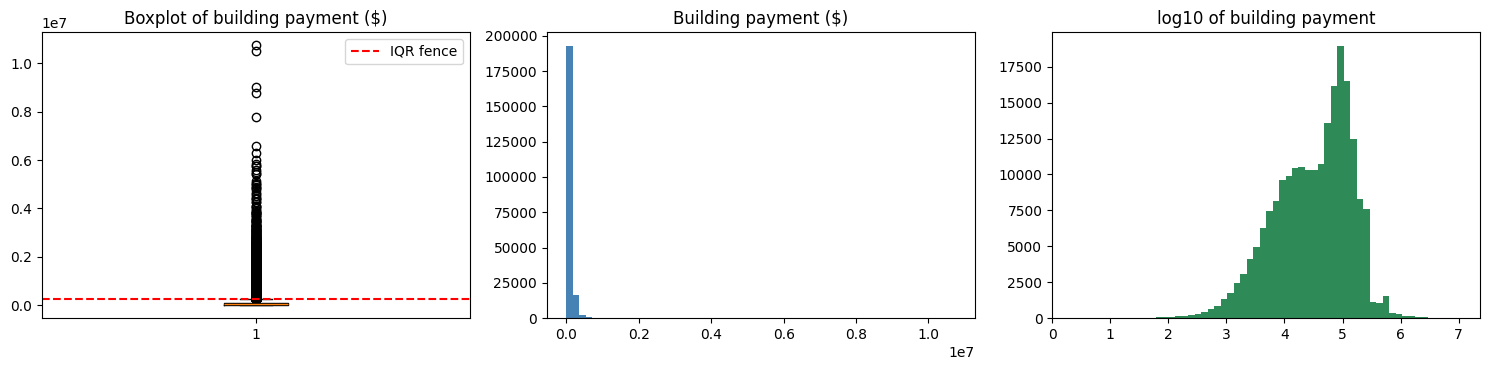

In [14]:
print(f'Median payment: ${pay.median():,.0f}    Mean payment: ${pay.mean():,.0f}    Max payment: ${pay.max():,.0f}')
big = df.nlargest(5, 'amountPaidOnBuildingClaim')[['amountPaidOnBuildingClaim', 'totalBuildingInsuranceCoverage', 'policyCount', 'state']]
print('\nThe five biggest payments:'); print(big)

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].boxplot(pay); ax[0].axhline(fence, color='red', ls='--', label='IQR fence'); ax[0].legend(); ax[0].set_title('Boxplot of building payment ($)')
ax[1].hist(pay, bins=60, color='steelblue'); ax[1].set_title('Building payment ($)')
ax[2].hist(np.log10(pay), bins=60, color='seagreen'); ax[2].set_title('log10 of building payment')
plt.tight_layout(); plt.show()

**What we conclude**
- The noise rules found only a few wrong values (35 negative payments, 90 buildings "built after the flood", 56 claims opened before
  the flood). The 6,339 policies that "started after the flood" are probably policies that were rewritten later, but we cannot be sure,
  so we turned those dates into missing.
- The IQR rule flags **11,714 payments (5.5%)** above $234,878. That is too many to all be errors.
- **Check 1:** 98.9% of the flagged payments are not more than the coverage that was bought, so they are possible.
- **Check 2:** the 634 payments over $1 million have a median of 28 policies and $5.9 million coverage. They are big condo buildings.
  The five biggest payments are all in Florida, with 36 to 198 policies each.
- So the big payments are **real outliers**, not noise, and we **keep** them. The raw histogram is not readable because almost all
  claims are on the left; on a log scale the shape is much easier to see. We will use the log scale in our charts.

## 5. Leakage: columns we cannot use

Some columns are only known **after** the claim is inspected or paid, for example the payment itself or the damage measured by the adjuster.
If we use them to predict the payment, the model "cheats". To find them we make a **correlation matrix** of the payment, the
columns filled in by the adjuster and some policy columns. A column with a very high correlation with the payment is suspicious.

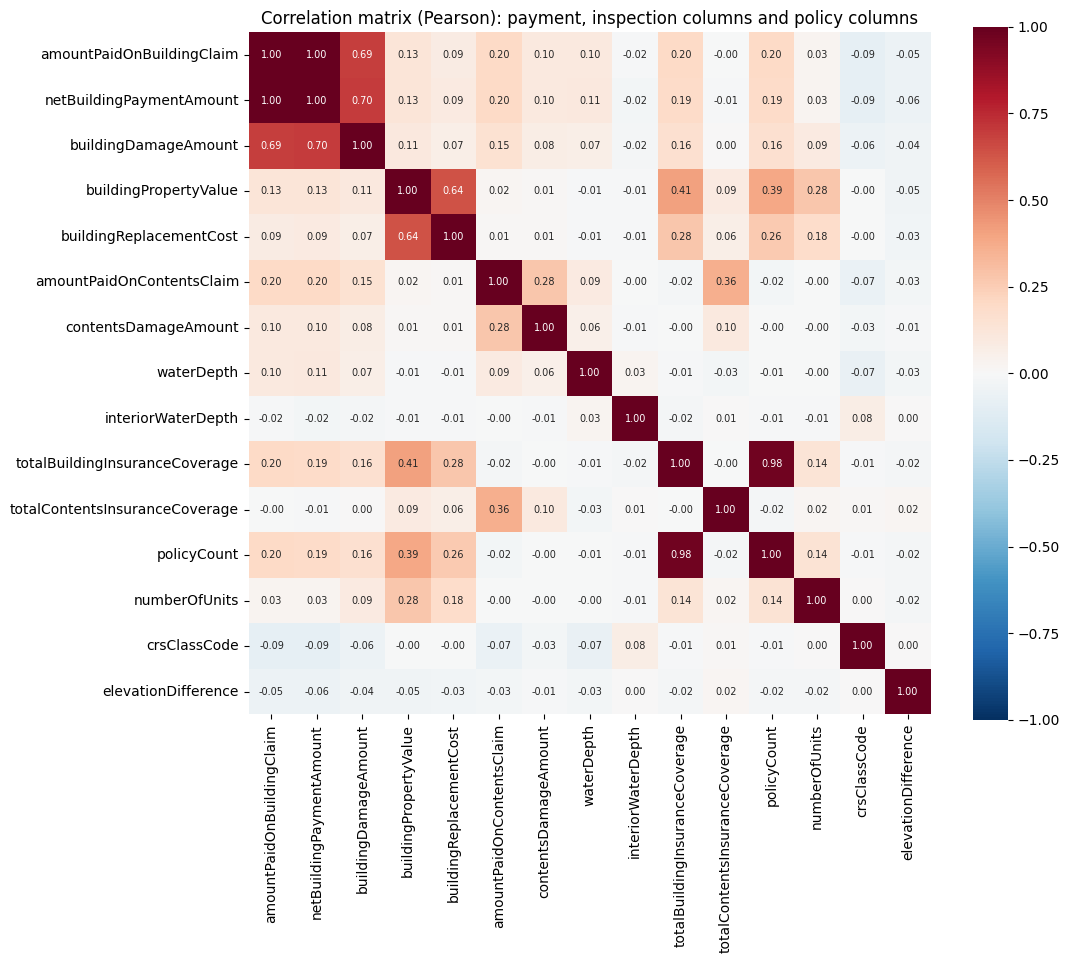

Correlation with amountPaidOnBuildingClaim:
netBuildingPaymentAmount          1.00
buildingDamageAmount              0.69
policyCount                       0.20
totalBuildingInsuranceCoverage    0.20
amountPaidOnContentsClaim         0.20
buildingPropertyValue             0.13
contentsDamageAmount              0.10
waterDepth                        0.10
buildingReplacementCost           0.09
numberOfUnits                     0.03
totalContentsInsuranceCoverage   -0.00
interiorWaterDepth               -0.02
elevationDifference              -0.05
crsClassCode                     -0.09


In [15]:
MATRIX_COLS = ['amountPaidOnBuildingClaim', 'netBuildingPaymentAmount', 'buildingDamageAmount', 'buildingPropertyValue',
               'buildingReplacementCost', 'amountPaidOnContentsClaim', 'contentsDamageAmount', 'waterDepth', 'interiorWaterDepth',
               'totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'policyCount', 'numberOfUnits',
               'crsClassCode', 'elevationDifference']
corr_matrix = df[MATRIX_COLS].corr()          # Pearson correlation (the pandas default)
plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7}, square=True)
plt.title('Correlation matrix (Pearson): payment, inspection columns and policy columns'); plt.show()
print('Correlation with amountPaidOnBuildingClaim:')
print(corr_matrix['amountPaidOnBuildingClaim'].drop('amountPaidOnBuildingClaim').sort_values(ascending=False).round(2).to_string())

In [16]:
LEAKAGE = ['netBuildingPaymentAmount', 'netContentsPaymentAmount', 'netIccPaymentAmount', 'amountPaidOnContentsClaim',
           'amountPaidOnIncreasedCostOfComplianceClaim', 'buildingDamageAmount', 'contentsDamageAmount',
           'buildingPropertyValue', 'buildingReplacementCost', 'contentsPropertyValue', 'contentsReplacementCost',
           'waterDepth', 'floodWaterDuration', 'interiorWaterDepth', 'exteriorWaterDepth', 'nonPaymentReasonBuilding',
           'nonPaymentReasonContents', 'mostRecentPaymentDate', 'totalSalvageRecovery', 'totalSubrogationRecovery']
LEAKAGE = [c for c in LEAKAGE if c in df.columns]
print('Columns known only after inspection or payment (we never use them as features):')
for c in LEAKAGE: print('  -', c)

Columns known only after inspection or payment (we never use them as features):
  - netBuildingPaymentAmount
  - netContentsPaymentAmount
  - netIccPaymentAmount
  - amountPaidOnContentsClaim
  - amountPaidOnIncreasedCostOfComplianceClaim
  - buildingDamageAmount
  - contentsDamageAmount
  - buildingPropertyValue
  - buildingReplacementCost
  - contentsPropertyValue
  - contentsReplacementCost
  - waterDepth
  - floodWaterDuration
  - interiorWaterDepth
  - exteriorWaterDepth
  - nonPaymentReasonBuilding
  - nonPaymentReasonContents
  - mostRecentPaymentDate
  - totalSalvageRecovery
  - totalSubrogationRecovery


**What the matrix shows**
- `netBuildingPaymentAmount` has a correlation of **1.00** with the payment: it *is* the payment.
- `buildingDamageAmount` has **0.69**, much more than any policy column (coverage and policy count are only 0.20).
  The Pearson correlation measures a straight-line relation, and the few very big condo claims make it lower than it would be on a
  log scale. But it is still the strongest "real" column, and it is measured by the adjuster **after** the flood.
- The other inspection columns (property value 0.13, water depth 0.10) are weaker, but they are also only known after the flood.

This was an important lesson for us: the columns that look the most useful are the ones we are not allowed to use.

## 6. New features

We make some new columns that are easier for a model to use.

| New column | How we make it |
|---|---|
| `building_age` | years between construction and the flood |
| `report_lag_days` | days between the flood and the date the claim was reported (0 to 365) |
| `zone` | 50+ flood zone codes grouped into FEMA's main groups (A, AE, AH, AO, V, X) |
| `deductible_usd` | deductible code turned into dollars (the letters are not in dollar order) |
| `named_storm` | 1 if the claim belongs to a named storm |
| `occupancy` | old (1-digit) and new (2-digit) occupancy codes translated to the same codes |
| `high_severity` | 1 if the building damage is in the top 20% (RQ2 target) |
| `damage_ratio` | building damage ÷ building value (0 to 1): how much of the building was damaged |
| `severity_band` | damage ratio in 4 ranges: minor (0-10%), moderate (10-25%), major (25-50%), severe (over 50%) (used in RQ3) |

In [17]:
df['building_age'] = (df['dateOfLoss'] - df['originalConstructionDate']).dt.days / 365.25
df['report_lag_days'] = (df['openDate'] - df['dateOfLoss']).dt.days.clip(lower=0, upper=365)
df['loss_year'] = df['dateOfLoss'].dt.year
df['loss_month'] = df['dateOfLoss'].dt.month

def zone_group(z):
    z = str(z).upper()
    if z in ['X', 'B', 'C']: return 'X'
    if z.startswith('V'): return 'V'
    if z in ['AE', 'AH', 'AO', 'A99', 'A']: return z
    if z.startswith('A'): return 'AE'       # old codes A1-A30 mean the same as AE
    return 'other'
df['zone'] = df['ratedFloodZone'].map(zone_group)

DEDUCTIBLE_USD = {'0': 500, '1': 1000, '2': 2000, '3': 3000, '4': 4000, '5': 5000, '9': 750, 'A': 10000, 'B': 15000,
                  'C': 20000, 'D': 25000, 'E': 50000, 'F': 1250, 'G': 1500, 'H': 200}
df['deductible_usd'] = df['buildingDeductibleCode'].astype(str).map(DEDUCTIBLE_USD)

df['named_storm'] = df['floodEvent'].notna().astype(int)
df['occupancy'] = df['occupancyType'].replace({1: 11, 2: 12, 3: 13, 4: 18, 6: 18})
df['foundation'] = df['foundationType'].astype(str).str.replace('.0', '', regex=False)

cutoff = df['buildingDamageAmount'].quantile(0.80)
df['high_severity'] = (df['buildingDamageAmount'] >= cutoff).astype(float)
df.loc[df['buildingDamageAmount'].isna(), 'high_severity'] = np.nan
print(f'High severity = building damage of at least ${cutoff:,.0f}')
print(df['high_severity'].value_counts(dropna=False))

# A range of severity, not only yes/no: damage as a share of the building value (used in RQ3)
value = df['buildingPropertyValue'].where(df['buildingPropertyValue'] > 0)
df['damage_ratio'] = df['buildingDamageAmount'] / value
print('\nDamage larger than the building value (impossible, set to missing):', int((df['damage_ratio'] > 1).sum()))
df.loc[df['damage_ratio'] > 1, 'damage_ratio'] = np.nan
SEVERITY_BANDS = ['minor (0-10%)', 'moderate (10-25%)', 'major (25-50%)', 'severe (over 50%)']
df['severity_band'] = pd.cut(df['damage_ratio'], bins=[0, 0.10, 0.25, 0.50, 1.0], labels=SEVERITY_BANDS, include_lowest=True).astype('string')
print('Severity bands (damage ratio):')
print(df['severity_band'].value_counts(dropna=False).reindex(SEVERITY_BANDS + [pd.NA]).to_string())

High severity = building damage of at least $105,397
high_severity
0.0    196988
1.0     49249
NaN     30333
Name: count, dtype: int64

Damage larger than the building value (impossible, set to missing): 1580
Severity bands (damage ratio):
severity_band
minor (0-10%)        96062
moderate (10-25%)    35248
major (25-50%)       48553
severe (over 50%)    37083
<NA>                 59624


## 7. Some charts to understand the data

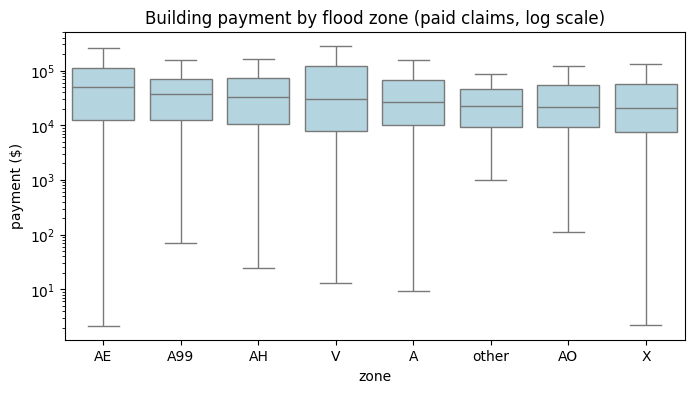

        count   median
zone                  
AE     157609  50928.0
A99       656  37681.0
AH       3080  33497.0
V        7803  29608.0
A        7646  27103.0
other      70  22944.0
AO       1158  21519.0
X       34910  21022.0


In [18]:
p = df[df['amountPaidOnBuildingClaim'] > 0]
order = p.groupby('zone')['amountPaidOnBuildingClaim'].median().sort_values(ascending=False).index
plt.figure(figsize=(8, 4))
sns.boxplot(data=p, x='zone', y='amountPaidOnBuildingClaim', order=order, showfliers=False, color='lightblue')
plt.yscale('log'); plt.title('Building payment by flood zone (paid claims, log scale)'); plt.ylabel('payment ($)'); plt.show()
print(p.groupby('zone')['amountPaidOnBuildingClaim'].agg(['count', 'median']).round(0).sort_values('median', ascending=False))

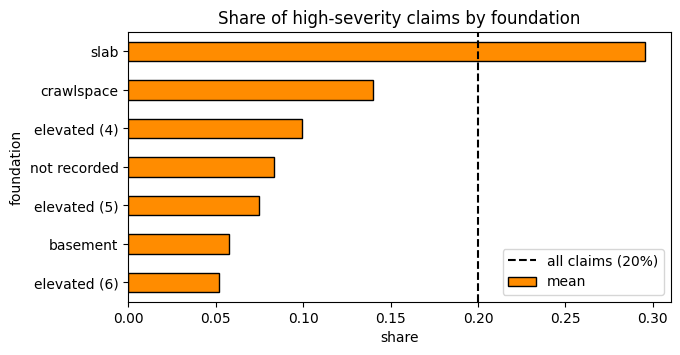

,count,mean
foundation,,
elevated (6),14870,0.052
basement,22148,0.058
elevated (5),18004,0.075
not recorded,22756,0.083
elevated (4),14861,0.100
crawlspace,18677,0.140
slab,134921,0.295


In [19]:
FOUNDATION_NAMES = {'1': 'slab', '2': 'basement', '3': 'crawlspace', '4': 'elevated (4)', '5': 'elevated (5)', '6': 'elevated (6)', '0': 'not recorded'}
sev = df[df['high_severity'].notna()].groupby(df['foundation'].map(FOUNDATION_NAMES))['high_severity'].agg(['count', 'mean'])
sev = sev[sev['count'] > 1000].sort_values('mean')
sev['mean'].plot.barh(color='darkorange', edgecolor='black', figsize=(7, 3.5))
plt.axvline(0.2, color='black', ls='--', label='all claims (20%)'); plt.legend()
plt.title('Share of high-severity claims by foundation'); plt.xlabel('share'); plt.show()
sev.round(3)

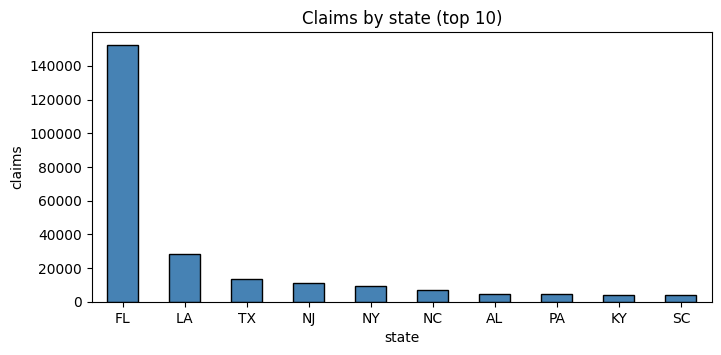

Florida has 55% of all claims.
floodEvent
Hurricane Helene    58018
Hurricane Ian       48634
Hurricane Ida       28273
Hurricane Milton    21594
Hurricane Sally      8109
Hurricane Idalia     5520
Name: count, dtype: int64


In [20]:
top_states = df['state'].value_counts().head(10)
top_states.plot.bar(color='steelblue', edgecolor='black', figsize=(8, 3.5))
plt.title('Claims by state (top 10)'); plt.ylabel('claims'); plt.xticks(rotation=0); plt.show()
print(f"Florida has {top_states.iloc[0] / len(df):.0%} of all claims.")
print(df['floodEvent'].value_counts().head(6))

**What the charts show**
- **Flood zone:** claims in zone **AE** (inside the 100-year floodplain) have the highest median payment ($50,928).
  Zone **X** (outside the mapped floodplain) has one of the lowest ($21,022). So the flood zone does matter for the payment.
- **Foundation:** **slab** buildings are high severity 29.5% of the time, much more than the 20% average. Elevated buildings are
  only 5-10%, and basements 5.8%. This is a first sign for RQ3: how the building stands on the ground is linked to the damage.
- **Place and storms:** Florida has 55% of all claims, and four hurricanes (Helene, Ian, Ida, Milton) have most of the named-storm claims.
  Our results will mostly describe Florida hurricanes.

## 8. Fill the missing values and save

We only fill the columns we will use as features. The method depends on the kind of column:
- **numbers:** the median (it is not pulled by big values like the mean)
- **categories:** a new category `unknown`, because a blank can carry information
- **yes / no columns:** blank means "no"

In [21]:
NUMBER_COLS = ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'deductible_usd', 'building_age',
               'numberOfUnits', 'policyCount', 'crsClassCode', 'report_lag_days',
               'latitude', 'longitude']
CATEGORY_COLS = ['zone', 'foundation', 'occupancy', 'numberOfFloorsInTheInsuredBuilding', 'state']
YES_NO_COLS = ['elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'primaryResidenceIndicator', 'rentalPropertyIndicator']

before = df[NUMBER_COLS + CATEGORY_COLS + YES_NO_COLS].isna().sum()
for c in NUMBER_COLS:
    df[c] = df[c].astype(float).fillna(df[c].astype(float).median())
for c in CATEGORY_COLS:
    df[c] = df[c].astype(str).replace({'nan': 'unknown', 'None': 'unknown', '<NA>': 'unknown'})
for c in YES_NO_COLS:
    df[c] = df[c].fillna(False).astype(int)
print(pd.DataFrame({'blanks before': before, 'blanks after': df[before.index].isna().sum()}))

                                    blanks before  blanks after
totalBuildingInsuranceCoverage                  0             0
totalContentsInsuranceCoverage                  1             0
deductible_usd                               6753             0
building_age                                 2322             0
numberOfUnits                                2718             0
policyCount                                     0             0
crsClassCode                                82370             0
report_lag_days                                 0             0
latitude                                     1826             0
longitude                                    1826             0
zone                                            0             0
foundation                                      0             0
occupancy                                       0             0
numberOfFloorsInTheInsuredBuilding            346             0
state                                   

In [22]:
KEEP = (['id', 'dateOfLoss', 'loss_year', 'loss_month', 'floodEvent', 'named_storm', 'countyCode', 'rating_system',
         'amountPaidOnBuildingClaim', 'buildingDamageAmount', 'high_severity', 'buildingPropertyValue', 'damage_ratio', 'severity_band']
        + NUMBER_COLS + CATEGORY_COLS + YES_NO_COLS)
import os
os.makedirs('data', exist_ok=True)
df[KEEP].to_parquet('data/claims_clean.parquet', index=False)
print('Saved data/claims_clean.parquet with', len(df), 'claims and', len(KEEP), 'columns')

Saved data/claims_clean.parquet with 276570 claims and 33 columns


## Summary of the cleaning

| Problem | What we did |
|---|---|
| 463 duplicate claims | removed |
| placeholder values (depth 99, elevation 9000+) | changed to missing |
| impossible dates, negative payments | changed to missing / to 0 |
| very big payments | kept (real outliers); we look at them on a log scale |
| leakage columns (payment, damage, water depth, ...) | never used as features |
| `elevationDifference` is 66% missing | not used as a feature; filling two thirds of a column with one value would invent the data |
| missing numbers in our features | filled with the median (for example 82,370 blanks in the CRS class) |
| missing categories | new category `unknown` |

**One thing we could do better:** we filled the blanks with the median of **all** years. Strictly, the median should come only from
the training years, because otherwise the test years give a little information to the training. The effect is very small here,
but we mention it.

The clean file `data/claims_clean.parquet` has 276,570 claims. High severity means building damage of at least **$105,397**
(49,249 claims; 30,333 claims have no damage figure and are not used in RQ2).

For RQ3 we also made a **range of severities**: the damage ratio (damage ÷ building value) in four bands, minor (0-10%), moderate (10-25%),
major (25-50%) and severe (over 50%). 1,580 claims had damage larger than the building value, which is impossible, so their ratio is missing.

## 9. Columns left after the cleaning

From the 84 columns we keep **33**. We put them into **groups** by the kind of information they give. The groups follow our RQ1
question ("flood-zone, construction, policy and geographic features"), plus the flood event, the time and the targets.
Columns in the same group describe the same thing, so they often go together (for example, the zone and the CRS class both say how
risky the *place* is), and we can talk about a whole group when we explain a model.

| Group | Why these columns belong together | Known when the claim is reported? |
|---|---|---|
| **ID and time** | identify the claim and say *when* it happened; we use the year to split train (2020-2023) and test (2024-2025) | yes |
| **Flood event** | describe the storm and how fast the claim was reported | yes |
| **Location (geographic)** | say *where* the building is | yes |
| **Flood risk of the place** | FEMA's risk rating of the location: the flood zone and the community's flood protection (CRS) | yes |
| **Building (construction)** | describe the building itself: age, foundation, use, size, elevation | yes |
| **Policy** | describe the insurance that was bought | yes |
| **Targets (outcomes)** | what happened after the flood: the payment (RQ1), the damage and high severity (RQ2), the damage ratio and severity band (RQ3) | **no**, so they are never used as features |

In [23]:
GROUP = {'id': 'ID and time', 'dateOfLoss': 'ID and time', 'loss_year': 'ID and time', 'loss_month': 'ID and time',
         'floodEvent': 'Flood event', 'named_storm': 'Flood event', 'report_lag_days': 'Flood event',
         'state': 'Location (geographic)', 'countyCode': 'Location (geographic)', 'latitude': 'Location (geographic)',
         'longitude': 'Location (geographic)',
         'zone': 'Flood risk of the place', 'crsClassCode': 'Flood risk of the place',
         'building_age': 'Building (construction)', 'foundation': 'Building (construction)', 'occupancy': 'Building (construction)',
         'numberOfFloorsInTheInsuredBuilding': 'Building (construction)', 'numberOfUnits': 'Building (construction)',
         'elevatedBuildingIndicator': 'Building (construction)', 'postFIRMConstructionIndicator': 'Building (construction)',
         'totalBuildingInsuranceCoverage': 'Policy', 'totalContentsInsuranceCoverage': 'Policy', 'deductible_usd': 'Policy',
         'policyCount': 'Policy', 'rating_system': 'Policy', 'primaryResidenceIndicator': 'Policy', 'rentalPropertyIndicator': 'Policy',
         'amountPaidOnBuildingClaim': 'Targets (outcomes)', 'buildingDamageAmount': 'Targets (outcomes)', 'high_severity': 'Targets (outcomes)',
         'buildingPropertyValue': 'Targets (outcomes)', 'damage_ratio': 'Targets (outcomes)', 'severity_band': 'Targets (outcomes)'}
NEW_COLUMNS = {'loss_year': ('Year of the flood (from dateOfLoss)', 'interval'),
               'loss_month': ('Month of the flood (from dateOfLoss)', 'interval'),
               'named_storm': ('1 if the claim belongs to a named storm', 'binary'),
               'report_lag_days': ('Days between the flood and the date the claim was opened (0-365)', 'ratio'),
               'rating_system': ('Risk Rating 2.0 or legacy (from rateMethod)', 'binary'),
               'zone': ('Flood zone group (A, AE, AH, AO, A99, V, X) made from ratedFloodZone', 'nominal'),
               'deductible_usd': ('Building deductible in dollars (from buildingDeductibleCode)', 'ratio'),
               'building_age': ('Age of the building in years at the time of the flood', 'ratio'),
               'occupancy': ('Occupancy code, old and new codes translated to the same codes', 'nominal'),
               'foundation': ('Foundation code (1 slab, 2 basement, 3 crawlspace, 4-6 elevated, 0 not recorded)', 'nominal'),
               'high_severity': ('1 if building damage is in the top 20% (RQ2 target)', 'binary'),
               'damage_ratio': ('Building damage divided by building value (0 to 1)', 'ratio'),
               'severity_band': ('Damage ratio in 4 ranges: minor, moderate, major, severe (RQ3 outcome)', 'ordinal')}
FEATURES_RQ1_RQ2 = ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'deductible_usd', 'building_age',
                    'numberOfUnits', 'policyCount', 'crsClassCode', 'report_lag_days', 'loss_month', 'named_storm',
                    'elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'primaryResidenceIndicator',
                    'rentalPropertyIndicator', 'zone', 'foundation', 'occupancy', 'numberOfFloorsInTheInsuredBuilding', 'state']
FEATURES_RQ3 = ['zone', 'foundation', 'numberOfFloorsInTheInsuredBuilding', 'occupancy', 'building_age', 'crsClassCode',
                'totalBuildingInsuranceCoverage']

rows = []
for c in KEEP:
    desc, kind = NEW_COLUMNS.get(c, COLUMNS.get(c, ('?', '?')))
    role = 'target' if GROUP[c] == 'Targets (outcomes)' else ('feature' if c in FEATURES_RQ1_RQ2 + FEATURES_RQ3 else 'not a feature')
    rows.append({'group': GROUP[c], 'column': c, 'description': desc, 'attribute type': kind, 'new column?': 'new' if c in NEW_COLUMNS else '',
                 'used in RQ1 / RQ2': 'yes' if c in FEATURES_RQ1_RQ2 else '', 'used in RQ3': 'yes' if c in FEATURES_RQ3 else '', 'role': role})
final_columns = pd.DataFrame(rows)
order = ['ID and time', 'Flood event', 'Location (geographic)', 'Flood risk of the place', 'Building (construction)', 'Policy', 'Targets (outcomes)']
final_columns['group'] = pd.Categorical(final_columns['group'], order, ordered=True)
final_columns = final_columns.sort_values(['group', 'column']).set_index(['group', 'column'])
print('Columns kept:', len(final_columns))
print(final_columns.groupby('group', observed=True).size().to_string())
final_columns

Columns kept: 33
group
ID and time                4
Flood event                3
Location (geographic)      4
Flood risk of the place    2
Building (construction)    7
Policy                     7
Targets (outcomes)         6


description  \
group                   column                                                                                                                 
ID and time             dateOfLoss                                                           Date the flood water first entered the building   
                        id                                                                                            Unique ID of the claim   
                        loss_month                                                                      Month of the flood (from dateOfLoss)   
                        loss_year                                                                        Year of the flood (from dateOfLoss)   
Flood event             floodEvent                                                       Name of the flood event (for example Hurricane Ian)   
                        named_storm                                                                  1 if the claim belongs to a named storm   
                        report_lag_days                                     Days between the flood and the date the claim was opened (0-365)   
Location (geographic)   countyCode                                                                                          County FIPS code   
                        latitude                                                                 Latitude, rounded to 0.1 degree for privacy   
                        longitude                                                               Longitude, rounded to 0.1 degree for privacy   
                        state                                                                                             State abbreviation   
Flood risk of the place crsClassCode                                    Community Rating System class (1 = best flood protection, 10 = none)   
                        zone                                            Flood zone group (A, AE, AH, AO, A99, V, X) made from ratedFloodZone   
Building (construction) building_age                                                   Age of the building in years at the time of the flood   
                        elevatedBuildingIndicator                                                     Building is elevated (NFIP definition)   
                        foundation                          Foundation code (1 slab, 2 basement, 3 crawlspace, 4-6 elevated, 0 not recorded)   
                        numberOfFloorsInTheInsuredBuilding                                   Code for the number of floors (5 = mobile home)   
                        numberOfUnits                                                              Number of units in a condominium building   
                        occupancy                                             Occupancy code, old and new codes translated to the same codes   
                        postFIRMConstructionIndicator                                    Building was built after the first flood map (FIRM)   
Policy                  deductible_usd                                          Building deductible in dollars (from buildingDeductibleCode)   
                        policyCount                                                                 Number of insured units under the policy   
                        primaryResidenceIndicator                                                     Building is the main home of the owner   
                        rating_system                                                            Risk Rating 2.0 or legacy (from rateMethod)   
                        rentalPropertyIndicator                                                                       Building is rented out   
                        totalBuildingInsuranceCoverage                                                 Building insurance bought, in dollars   
                        totalContentsInsuranceCoverage                                           

**Notes on the table**
- `state` is used in RQ1 and RQ2 as `state_group`: the 10 states with the most claims, and "other" for the rest (too many states
  would give too many one-hot columns).
- `latitude`, `longitude` and `countyCode` are kept in the file, but we do not use them as features: with the coordinates, a model
  learns *where past storms hit*, which does not help for a new storm.
- `floodEvent` and `rating_system` are kept to **describe** the results (for example "Hurricane Ian claims"), not to train models.
- The **targets** are never features. `buildingDamageAmount` is kept to build `high_severity` and for the leakage test in RQ1;
  `buildingPropertyValue` is kept only to build `damage_ratio` and `severity_band`, which describe the clusters in RQ3.